In [1]:
%matplotlib inline
import os
import re
import itertools
from itertools import combinations
import glob
import pickle
import argparse

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import multiprocess as mp
import numpy as np
import pandas as pd
import bioframe as bf
import cooltools
import cooler
from matplotlib import gridspec
from matplotlib.gridspec import GridSpec
import matplotlib.colors as colors
from matplotlib.colors import ListedColormap
from collections import OrderedDict
import plotly.express as px
import gzip
import plotly.graph_objects as go
import warnings
warnings.filterwarnings('ignore')

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/cooltools/lib/numutils.py:651: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit  # (nopython=True)
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/cooltools/lib/numutils.py:726: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit  # (nopython=True)


# DNA FISH files of whole cell information measured by aivia software (3D objects) 

In [2]:
#organize all probes whole cell location information together
# Define the base directory
base_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish/"
stages1 = ['Wholecell_H1', 'Wholecell_DE', 'Wholecell_HB', 'Wholecell_iHep', 'Wholecell_mHep']
probes = ['Chr11_107_chr11_119', 'Chr11_11_chr11_41', 'Chr11_88_chr11_41', 'Chr2_100_chr2_79', 'Chr2_2_chr2_32']

# Initialize the dictionary
wholecell_probes = {probe: {} for probe in probes}

# Populate the dictionary for each probe and stage
for probe in probes:
    for stage in stages1:
        wholecell_probes[probe][stage] = {}
        stage_dir = os.path.join(base_dir, probe, 'batch_of_jobs', stage)  # Correct directory path

        if not os.path.isdir(stage_dir):
            print(f"Warning: Directory {stage_dir} does not exist.")
            continue

        # List all folders in the stage directory
        folder_list = [os.path.join(stage_dir, folder) for folder in os.listdir(stage_dir) if os.path.isdir(os.path.join(stage_dir, folder))]

        for i, folder in enumerate(folder_list, start=1):
            wholecell_probes[probe][stage][f'cell{i}'] = {}

            try:
                wholecell_probes[probe][stage][f'cell{i}']['Cell_info'] = pd.read_csv(
                    os.path.join(folder, "Measurements/Measurements_Set_Cell Membranes.csv"),
                    header=0
                )
            except FileNotFoundError:
                wholecell_probes[probe][stage][f'cell{i}']['Cell_info'] = None  # Handle missing files

            try:
                wholecell_probes[probe][stage][f'cell{i}']['Territory_info'] = pd.read_csv(
                    os.path.join(folder, "Measurements/Measurements_Set_Vesicles - 1.csv"),
                    header=0
                )
            except FileNotFoundError:
                wholecell_probes[probe][stage][f'cell{i}']['Territory_info'] = None

            try:
                wholecell_probes[probe][stage][f'cell{i}']['loci647_info'] = pd.read_csv(
                    os.path.join(folder, "Measurements/Measurements_Set_Vesicles - 2.csv"),
                    header=0
                )
            except FileNotFoundError:
                wholecell_probes[probe][stage][f'cell{i}']['loci647_info'] = None

            try:
                wholecell_probes[probe][stage][f'cell{i}']['loci550_info'] = pd.read_csv(
                    os.path.join(folder, "Measurements/Measurements_Set_Vesicles - 3.csv"),
                    header=0
                )
            except FileNotFoundError:
                wholecell_probes[probe][stage][f'cell{i}']['loci550_info'] = None

In [3]:
len(folder_list) 

71

In [4]:
wholecell_probes['Chr2_2_chr2_32']['Wholecell_H1']['cell1']['Cell_info']

,Sphericity,Surface Area (µm²),Volume (µm³),Surface Area To Volume Ratio,Contained Vesicle Count,Centroid X (µm),Centroid Y (µm),Centroid Z (µm),Mean Intensity - Want (2),Timeframe
0,0.522641,273.946668,161.093638,1.700543,23,6.580679,6.015323,0.742674,254.853499,0


In [6]:
def merge_and_select_rows(df):
    """
    Merge rows in the DataFrame based on the difference in 'Centroid X (µm)' 
    or 'Centroid Y (µm)' being less than 0.15. If the resulting DataFrame 
    has more than two rows, select two rows based on specific conditions:
    - 'Sphericity' > 0.5
    - 0.03 < 'Volume (µm³)' < 0.5
    - 'Distance to Nearest Edge of Cell (µm)' < 2.5
    
    If the input DataFrame is empty or missing required columns, return an empty DataFrame
    with the specified column names.

    Parameters:
    df (pd.DataFrame): Input DataFrame containing the relevant columns.

    Returns:
    pd.DataFrame: Modified DataFrame with merged and selected rows, or an empty DataFrame.
    """
    # Define the column names for the DataFrame
    column_names = [
        'Sphericity', 'Volume (µm³)', 'Distance to Center of Cell (µm)', 
        'Distance to Center of Nucleus (µm)', 'Distance to Nearest Edge of Cell (µm)', 
        'Distance to Nearest Edge of Nucleus (µm)', 'Centroid X (µm)', 
        'Centroid Y (µm)', 'Centroid Z (µm)', 'Timeframe'
    ]

    # If the input DataFrame is None or does not contain the required columns, return an empty DataFrame
    if df is None or not set(column_names).issubset(df.columns):
        return pd.DataFrame(columns=column_names)

    # List to store indices of rows to remove and new rows to add
    rows_to_remove = []
    new_rows = []

    # Iterate over all pairs of rows
    if len(df) > 2:  # Ensure there are enough rows for comparisons
        for i in range(len(df)):
            for j in range(i + 1, len(df)):  # Compare only subsequent rows
                # Check if Centroid X or Centroid Y differences are < 0.15
                if (abs(df.at[i, 'Centroid X (µm)'] - df.at[j, 'Centroid X (µm)']) < 0.15 or
                        abs(df.at[i, 'Centroid Y (µm)'] - df.at[j, 'Centroid Y (µm)']) < 0.15):
                    
                    # Compute mean and sum for the rows
                    mean_cols = [
                        'Sphericity', 'Distance to Center of Cell (µm)', 'Distance to Nearest Edge of Cell (µm)',
                        'Centroid X (µm)', 'Centroid Y (µm)', 'Centroid Z (µm)', 'Timeframe'
                    ]
                    sum_col = 'Volume (µm³)'

                    # Compute new row values
                    new_row = df.loc[[i, j], mean_cols].mean(axis=0).to_dict()
                    new_row['Volume (µm³)'] = df.loc[[i, j], sum_col].sum()

                    # Add to new rows list
                    new_rows.append(new_row)

                    # Mark rows for removal
                    rows_to_remove.extend([i, j])

    # Remove duplicate rows and keep unique indices
    rows_to_remove = list(set(rows_to_remove))

    # Drop the rows from the original DataFrame
    df = df.drop(index=rows_to_remove).reset_index(drop=True)

    # Append the new rows to the DataFrame
    new_rows_df = pd.DataFrame(new_rows)
    df = pd.concat([df, new_rows_df], ignore_index=True)

    # Reset index for final DataFrame
    df.reset_index(drop=True, inplace=True)

    # If more than 2 rows, filter based on the conditions
    if len(df) > 2:
        df = df[
            (df['Sphericity'] > 0.5) &
            (df['Volume (µm³)'] > 0.03) &
            (df['Volume (µm³)'] < 0.5) &
            (df['Distance to Nearest Edge of Cell (µm)'] < 2.5)
        ]

        # Select the first two rows that meet the criteria
        df = df.head(2)

    return df


In [7]:
# test "merge_and_select_rows" function
data = {
    'Sphericity': [0.560381, 0.564669, 0.877559],
    'Volume (µm³)': [0.066747, 0.037481, 0.076407],
    'Distance to Center of Cell (µm)': [5.368728, 5.402172, 5.055597],
    'Distance to Center of Nucleus (µm)': [None, None, None],
    'Distance to Nearest Edge of Cell (µm)': [0.761737, 0.827284, 0.429710],
    'Distance to Nearest Edge of Nucleus (µm)': [None, None, None],
    'Centroid X (µm)': [5.827936, 5.877097, 9.959258],
    'Centroid Y (µm)': [9.545409, 9.656315, 10.529534],
    'Centroid Z (µm)': [0.836382, 0.836186, 1.212963],
    'Timeframe': [0, 0, 0],
}

# Create DataFrame
data = pd.DataFrame(data)

# Call the function
data_new = merge_and_select_rows(data)

data_new
#data

,Sphericity,Volume (µm³),Distance to Center of Cell (µm),Distance to Center of Nucleus (µm),Distance to Nearest Edge of Cell (µm),Distance to Nearest Edge of Nucleus (µm),Centroid X (µm),Centroid Y (µm),Centroid Z (µm),Timeframe
0,0.877559,0.076407,5.055597,None,0.429710,None,9.959258,10.529534,1.212963,0.0
1,0.562525,0.104228,5.385450,NaN,0.794511,NaN,5.852517,9.600862,0.836284,0.0


In [8]:
def calculate_radii(volume, surface_area):
    """
    Calculate the equatorial and polar radii of a pancake-like object.
    
    Parameters:
    - volume (float): Volume of the object (µm³)
    - surface_area (float): Surface area of the object (µm²)
    
    Returns:
    - a (float): Equatorial radius (µm)
    - c (float): Polar radius (µm)
    """
    # Calculate equatorial radius (a)
    a = np.sqrt(surface_area / (2 * np.pi))
    
    # Calculate polar radius (c)
    c = volume / (np.pi * a**2)
    
    return a, c

def process_cell_info(cell_info):
    """
    Process the Cell_info DataFrame to select the row with the largest volume
    and calculate equatorial and polar radii.
    
    Parameters:
    - cell_info (DataFrame): Input DataFrame containing cell information
    
    Returns:
    - processed_info (DataFrame): A single-row DataFrame with calculated radii
    """
    # Check if the DataFrame is not empty
    if cell_info.empty:
        raise ValueError("The input DataFrame is empty.")
    
    # Select the row with the largest Volume (µm³)
    largest_volume_row = cell_info.loc[cell_info['Volume (µm³)'].idxmax()]
    
    # Calculate radii for the selected row
    volume = largest_volume_row['Volume (µm³)']
    surface_area = largest_volume_row['Surface Area (µm²)']
    equatorial_radius, polar_radius = calculate_radii(volume, surface_area)
    
    # Convert the selected row to a DataFrame and add calculated radii
    largest_volume_row = largest_volume_row.to_frame().T
    largest_volume_row['Equatorial Radius (µm)'] = equatorial_radius
    largest_volume_row['Polar Radius (µm)'] = polar_radius
    
    return largest_volume_row.reset_index(drop=True)

In [9]:
# Apply transformations to wholecell_probes dataset
for probe, stages in wholecell_probes.items():
    for stage, cells in stages.items():
        last_valid_cell_info = None  # Reset for each stage

        for cell_id, data in cells.items():
            if 'Cell_info' in data:
                if data['Cell_info'] is not None and not data['Cell_info'].empty:
                    # Process the Cell_info if it's not empty
                    data['Cell_info'] = process_cell_info(data['Cell_info'])
                    last_valid_cell_info = data['Cell_info']  # Update the last valid Cell_info
                elif last_valid_cell_info is not None:
                    # Use the last valid Cell_info if current one is empty
                    data['Cell_info'] = last_valid_cell_info.copy()
                else:
                    # If no previous valid Cell_info exists, raise a warning
                    print(f"Warning: No valid Cell_info found for {probe}, {stage}, {cell_id}")

            if 'loci647_info' in data and data['loci647_info'] is not None:
                data['loci647_info'] = merge_and_select_rows(data['loci647_info'])

            if 'loci550_info' in data and data['loci550_info'] is not None:
                data['loci550_info'] = merge_and_select_rows(data['loci550_info'])

In [10]:
wholecell_probes['Chr2_2_chr2_32']['Wholecell_H1']['cell1']['Territory_info']

,Sphericity,Volume (µm³),Distance to Center of Cell (µm),Distance to Center of Nucleus (µm),Distance to Nearest Edge of Cell (µm),Distance to Nearest Edge of Nucleus (µm),Centroid X (µm),Centroid Y (µm),Centroid Z (µm),Timeframe
0,0.413359,15.389231,4.210865,NaN,0.715005,NaN,7.743594,9.40634,0.742687,0
1,0.340100,21.431433,3.414289,NaN,0.873148,NaN,8.354241,6.15131,0.742675,0
2,0.647431,4.227973,5.656000,NaN,0.572773,NaN,1.207906,5.92863,0.742771,0


In [ ]:
#summary all of information together

In [11]:
def create_summary_table(dataset):
    """
    Create a summary DataFrame for all cells in the dataset, handling empty or missing data.
    
    Parameters:
    - dataset: Dictionary containing cell data for multiple cells.
    
    Returns:
    - pd.DataFrame: Concatenated summary DataFrame for all cells
    """
    # Initialize an empty dictionary to hold the DataFrames for each cell
    df_set = {}

    # Iterate through each cell's data
    for cell_id, cell_data in dataset.items():
        try:
            # Skip entries with missing keys or empty data
            if not all(k in cell_data for k in ['Cell_info', 'Territory_info', 'loci550_info', 'loci647_info']):
                print(f"Skipping cell ID {cell_id} due to missing keys.")
                continue

            if cell_data['Cell_info'].empty or cell_data['Territory_info'].empty:
                print(f"Skipping cell ID {cell_id} due to empty data.")
                continue

            # Initialize a new DataFrame for the current cell
            df = pd.DataFrame(index=[cell_id])  # Set cell_id as the row name

            # Populate the DataFrame with the relevant data for the current cell
            df['cell_volumn'] = cell_data['Cell_info']['Volume (µm³)'].iloc[0]
            df['cell_equatorial_radius'] = cell_data['Cell_info']['Equatorial Radius (µm)'].iloc[0]
            df['cell_polar_radius'] = cell_data['Cell_info']['Polar Radius (µm)'].iloc[0]
            df['cell_location_x'] = cell_data['Cell_info']['Centroid X (µm)'].iloc[0]
            df['cell_location_y'] = cell_data['Cell_info']['Centroid Y (µm)'].iloc[0]
            df['cell_location_z'] = cell_data['Cell_info']['Centroid Z (µm)'].iloc[0]

            # Calculating territory volumes
            df['Territory_volumn_abs'] = cell_data['Territory_info']['Volume (µm³)'].sum()
            df['Territory_volumnofcell_ratio'] = df['Territory_volumn_abs'] / df['cell_volumn']
            df['Territory_Sphericity'] = cell_data['Territory_info']['Sphericity'].mean()

            # Calculating mean distance to the center of the nucleus
            if 'Distance to Center of Cell (µm)' in cell_data['Territory_info']:
                df['Territory_radius_mean_abs'] = cell_data['Territory_info']['Distance to Center of Cell (µm)'].mean()
            else:
                df['Territory_radius_mean_abs'] = pd.NA
            df['Territory_radius_mean_ratio'] = df['Territory_radius_mean_abs'] / df['cell_equatorial_radius']

            # Adding loci550 information
            loci550_info = cell_data['loci550_info']
            df['550loci1_location_x'] = loci550_info['Centroid X (µm)'].iloc[0] if len(loci550_info) > 0 else pd.NA
            df['550loci1_location_y'] = loci550_info['Centroid Y (µm)'].iloc[0] if len(loci550_info) > 0 else pd.NA
            df['550loci1_location_z'] = loci550_info['Centroid Z (µm)'].iloc[0] if len(loci550_info) > 0 else pd.NA
            df['550loci2_location_x'] = loci550_info['Centroid X (µm)'].iloc[1] if len(loci550_info) > 1 else pd.NA
            df['550loci2_location_y'] = loci550_info['Centroid Y (µm)'].iloc[1] if len(loci550_info) > 1 else pd.NA
            df['550loci2_location_z'] = loci550_info['Centroid Z (µm)'].iloc[1] if len(loci550_info) > 1 else pd.NA
            
            df['550loci1_radius_abs'] = loci550_info['Distance to Center of Cell (µm)'].iloc[0] if len(loci550_info) > 0 else pd.NA
            df['550loci1_radius_ratio'] = df['550loci1_radius_abs'] / df['cell_equatorial_radius'] if len(loci550_info) > 0 else pd.NA
            df['550loci2_radius_abs'] = loci550_info['Distance to Center of Cell (µm)'].iloc[1] if len(loci550_info) > 1 else pd.NA
            df['550loci2_radius_ratio'] = df['550loci2_radius_abs'] / df['cell_equatorial_radius'] if len(loci550_info) > 1 else pd.NA

            # Adding loci647 information
            loci647_info = cell_data['loci647_info']
            df['647loci1_location_x'] = loci647_info['Centroid X (µm)'].iloc[0] if len(loci647_info) > 0 else pd.NA
            df['647loci1_location_y'] = loci647_info['Centroid Y (µm)'].iloc[0] if len(loci647_info) > 0 else pd.NA
            df['647loci1_location_z'] = loci647_info['Centroid Z (µm)'].iloc[0] if len(loci647_info) > 0 else pd.NA
            df['647loci2_location_x'] = loci647_info['Centroid X (µm)'].iloc[1] if len(loci647_info) > 1 else pd.NA
            df['647loci2_location_y'] = loci647_info['Centroid Y (µm)'].iloc[1] if len(loci647_info) > 1 else pd.NA
            df['647loci2_location_z'] = loci647_info['Centroid Z (µm)'].iloc[1] if len(loci647_info) > 1 else pd.NA

            df['647loci1_radius_abs'] = loci647_info['Distance to Center of Cell (µm)'].iloc[0] if len(loci647_info) > 0 else pd.NA
            df['647loci1_radius_ratio'] = df['647loci1_radius_abs'] / df['cell_equatorial_radius'] if len(loci647_info) > 0 else pd.NA
            df['647loci2_radius_abs'] = loci647_info['Distance to Center of Cell (µm)'].iloc[1] if len(loci647_info) > 1 else pd.NA
            df['647loci2_radius_ratio'] = df['647loci2_radius_abs'] / df['cell_equatorial_radius'] if len(loci647_info) > 1 else pd.NA

            # Store the DataFrame in the dictionary
            df_set[cell_id] = df

        except Exception as e:
            print(f"Error processing cell ID {cell_id}: {e}")
            continue

    # Concatenate all the DataFrames into one final DataFrame
    if df_set:
        final_summary_df = pd.concat(df_set.values(), axis=0)
        final_summary_df.reset_index(inplace=True)
        final_summary_df.rename(columns={'index': 'cell_id'}, inplace=True)
        return final_summary_df
    else:
        print("No valid data to summarize.")
        return pd.DataFrame()  # Return an empty DataFrame if no valid data is found


In [170]:
# apply the summary function on wholecell_probes

# Dictionary to store summary tables
wholecell_summary = {}

# Iterate over probes and stages
for probe, stages in wholecell_probes.items():
    wholecell_summary[probe] = {}  # Initialize nested dictionary for each probe
    for stage, cells in stages.items():
        # Apply create_summary_table to each stage's data
        summary_df = create_summary_table(cells)  # Correctly assign the result to a variable
        wholecell_summary[probe][stage] = summary_df  # Store the summary table in the dictionary
        
        # Define the output filename
#        filename = f"/home/xiangru.huo-umw/scHiC/scripts/DNAfish/{probe}_{stage}_summary.csv"
        # Save the DataFrame to a CSV file
#        summary_df.to_csv(filename, index=False)

# Display the last summary table generated for the final probe and stage
wholecell_summary[probe][stage]

Skipping cell ID cell1 due to empty data.
Skipping cell ID cell5 due to empty data.
Skipping cell ID cell6 due to empty data.
Skipping cell ID cell8 due to empty data.
Skipping cell ID cell10 due to empty data.
Skipping cell ID cell11 due to empty data.
Skipping cell ID cell12 due to empty data.
Skipping cell ID cell13 due to empty data.
Skipping cell ID cell15 due to empty data.
Skipping cell ID cell16 due to empty data.
Skipping cell ID cell17 due to empty data.
Skipping cell ID cell19 due to empty data.
Skipping cell ID cell23 due to empty data.
Skipping cell ID cell24 due to empty data.
Skipping cell ID cell26 due to empty data.
Skipping cell ID cell27 due to empty data.
Skipping cell ID cell28 due to empty data.
Skipping cell ID cell34 due to empty data.
Skipping cell ID cell35 due to empty data.
Skipping cell ID cell38 due to empty data.
Skipping cell ID cell39 due to empty data.
Skipping cell ID cell40 due to empty data.
Skipping cell ID cell41 due to empty data.
Skipping cell I

,cell_id,cell_volumn,cell_equatorial_radius,cell_polar_radius,cell_location_x,cell_location_y,cell_location_z,Territory_volumn_abs,Territory_volumnofcell_ratio,Territory_Sphericity,...,647loci1_location_x,647loci1_location_y,647loci1_location_z,647loci2_location_x,647loci2_location_y,647loci2_location_z,647loci1_radius_abs,647loci1_radius_ratio,647loci2_radius_abs,647loci2_radius_ratio
0,cell1,277.415213,6.327129,2.205804,16.364151,14.657829,1.831056,51.230645,0.184671,0.858546,...,15.663628,16.096907,2.199260,13.213915,16.994502,2.198889,1.845089,0.291616,4.066698,0.642740
1,cell2,352.997123,6.680538,2.517668,15.650446,15.323577,2.264740,171.632476,0.486215,0.721769,...,13.485912,14.315090,3.441981,18.091756,15.151412,3.240801,2.863180,0.428585,2.637308,0.394775
2,cell3,227.117672,6.615329,1.651955,15.528734,14.318586,1.106263,31.114098,0.136995,0.788886,...,15.296390,9.663264,1.107803,15.503553,9.955857,1.105615,4.666968,0.705478,4.398404,0.664881
3,cell4,310.765755,6.738336,2.178602,15.106674,13.822039,1.718523,57.246346,0.184211,0.851949,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,cell5,242.185085,6.057024,2.101256,15.882030,13.431078,1.709463,38.732081,0.159928,0.818291,...,17.921404,10.314004,1.915916,19.292149,13.227416,1.995908,3.679452,0.607469,3.412559,0.563405
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,cell67,488.048530,7.443805,2.803646,17.458086,18.290249,2.620699,80.392909,0.164723,0.741468,...,12.067828,5.087446,1.635137,19.171821,20.193146,3.635690,4.089703,0.549410,2.860747,0.384313
67,cell68,327.609888,6.628851,2.373180,14.151812,15.610883,2.317431,38.626880,0.117905,0.793234,...,10.651422,16.839927,1.542237,NaN,NaN,NaN,4.225399,0.637426,NaN,NaN
68,cell69,684.875080,8.232213,3.216832,13.116417,12.501117,3.148321,92.610484,0.135222,0.704777,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
69,cell70,808.654071,9.644762,2.767132,13.435885,13.039679,2.319814,60.161381,0.074397,0.687221,...,17.957849,18.026369,1.158451,17.597009,18.886422,1.148167,6.779855,0.702957,7.215225,0.748098


In [171]:
wholecell_summary[probe]['Wholecell_DE']

,cell_id,cell_volumn,cell_equatorial_radius,cell_polar_radius,cell_location_x,cell_location_y,cell_location_z,Territory_volumn_abs,Territory_volumnofcell_ratio,Territory_Sphericity,...,647loci1_location_x,647loci1_location_y,647loci1_location_z,647loci2_location_x,647loci2_location_y,647loci2_location_z,647loci1_radius_abs,647loci1_radius_ratio,647loci2_radius_abs,647loci2_radius_ratio
0,cell1,108.817369,4.661098,1.594307,12.642283,13.558537,2.008287,10.202352,0.093757,0.572334,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,cell2,171.519879,5.620800,1.728098,13.729765,13.995165,1.878959,12.920439,0.075329,0.461167,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,cell3,179.752221,5.259975,2.068031,13.078024,11.855539,2.036096,5.188237,0.028863,0.550775,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,cell4,68.524545,4.295086,1.182367,8.456517,9.039967,0.828506,0.868117,0.012669,0.666120,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,cell5,132.406390,4.888027,1.763973,13.353710,13.097638,1.673938,24.505972,0.185081,0.522866,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,cell79,335.002947,6.640499,2.418228,9.762790,9.511278,2.130034,13.946246,0.041630,0.505227,...,8.648424,6.109946,1.061783,11.772858,10.464729,3.253288,3.491595,0.525803,2.786101,0.419562
76,cell81,348.669734,7.399254,2.027163,9.484850,12.056035,1.601221,63.024831,0.180758,0.547778,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
77,cell82,161.418235,6.130598,1.367090,9.959604,11.277229,0.897409,20.106848,0.124564,0.527700,...,5.907096,7.778549,0.899085,13.305749,6.709717,0.448083,5.225086,0.852296,5.311824,0.866445
78,cell83,106.383237,4.642163,1.571385,13.386019,12.077079,1.285078,1.073398,0.010090,0.548075,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [172]:
# Simplified function to calculate normalized radius distance
def calculate_all_loci_distances(df, loci_columns, stretch_factor):
    """
    Calculate distances from the cell center for all loci in the DataFrame.

    Parameters:
        df (DataFrame): Input DataFrame containing location coordinates.
        loci_columns (list): List of loci identifiers (without suffix).
        stretch_factor (float): Factor to adjust the z-dimension.

    Returns:
        DataFrame: The input DataFrame with added distance columns.
    """
    # Check if DataFrame is empty and skip if true
    if df.empty:
        print("DataFrame is empty, skipping...")
        return df  # Return as is, nothing to process
    
    # Ensure required columns are present
    required_columns = ['cell_location_x', 'cell_location_y', 'cell_location_z'] + \
                       [f"{locus}_location_x" for locus in loci_columns] + \
                       [f"{locus}_location_y" for locus in loci_columns] + \
                       [f"{locus}_location_z" for locus in loci_columns]

    missing_columns = [col for col in required_columns if col not in df.columns]
    if missing_columns:
        raise KeyError(f"Missing required columns: {missing_columns}")

    # Calculate distances
    center_x, center_y, center_z = df['cell_location_x'], df['cell_location_y'], df['cell_location_z']
    for locus in loci_columns:
        df[f'{locus}_distance_from_center'] = np.sqrt(
            (df[f'{locus}_location_x'] - center_x) ** 2 +
            (df[f'{locus}_location_y'] - center_y) ** 2 +
            ((df[f'{locus}_location_z'] - center_z) * stretch_factor) ** 2
        )
    return df

In [185]:
# Main loop for processing
for probe in probes:
    wholecell_summary_normalized[probe] = {}
    stages_and_factors = {
        'Wholecell_H1': 2,
        'Wholecell_DE': 2,
        'Wholecell_HB': 2,
        'Wholecell_iHep': 2,
        'Wholecell_mHep': 2
    }

    for stage, stretch_factor in stages_and_factors.items():
        df = wholecell_summary[probe][stage].copy()

        # Check if the DataFrame is empty and skip processing if true
        if df.empty:
            print(f"Skipping empty DataFrame for probe '{probe}', stage '{stage}'")
            continue

        try:
            # Process and store results
            result_df = calculate_all_loci_distances(df, loci_columns, stretch_factor)            
            wholecell_summary_normalized[probe][stage] = result_df
            
        except KeyError as e:
            print(f"Error for probe '{probe}', stage '{stage}': {e}")
        except Exception as e:
            print(f"Unexpected error for probe '{probe}', stage '{stage}': {e}")

Skipping empty DataFrame for probe 'Chr11_88_chr11_41', stage 'Wholecell_HB'


In [191]:
wholecell_summary_normalized[probe]['Wholecell_H1'].head()

,cell_id,cell_volumn,cell_equatorial_radius,cell_polar_radius,cell_location_x,cell_location_y,cell_location_z,Territory_volumn_abs,Territory_volumnofcell_ratio,Territory_Sphericity,...,647loci2_location_y,647loci2_location_z,647loci1_radius_abs,647loci1_radius_ratio,647loci2_radius_abs,647loci2_radius_ratio,550loci1_distance_from_center,550loci2_distance_from_center,647loci1_distance_from_center,647loci2_distance_from_center
0,cell1,161.093638,6.603027,1.176095,6.580679,6.015323,0.742674,41.048636,0.254812,0.466964,...,7.536508,0.888738,5.036116,0.762698,3.237336,0.490281,2.879837,3.499923,4.509206,1.925835
1,cell3,124.231480,5.858615,1.152105,8.403082,7.750140,0.742674,5.127556,0.041274,0.365903,...,10.448623,1.054782,2.858317,0.487883,3.847922,0.656797,3.631695,NaN,2.962545,3.758168
2,cell4,113.940766,5.237167,1.322320,9.120178,7.419428,1.039744,12.094017,0.106143,0.521173,...,9.892235,0.879567,3.590668,0.685613,2.585129,0.493612,2.733014,4.436421,3.485452,2.724566
3,cell5,96.232636,5.302699,1.089378,9.010453,8.259629,0.742674,18.668561,0.193994,0.474493,...,NaN,NaN,1.967623,0.371061,NaN,NaN,1.614683,NaN,2.077996,NaN
4,cell6,177.927183,6.208387,1.469383,8.589573,8.243189,1.039744,112.232859,0.630780,0.628354,...,6.371045,1.337280,3.494434,0.562857,1.789243,0.288198,4.236097,6.259806,3.431990,2.049867


In [192]:
# Function to calculate the relative radius distance of a locus for each stage with specific cell dimensions
def calculate_relative_radius(df, loci_columns, stretch_factor, cell_dimensions):
    """
    Calculate relative radius distance for each locus for a given cell at different stages.
    
    Parameters:
        df (DataFrame): Input DataFrame containing location coordinates.
        loci_columns (list): List of loci identifiers (without suffix).
        stretch_factor (float): Factor to adjust the z-dimension.
        cell_dimensions (tuple): The cell dimensions (a, b, c) for the current stage.
        
    Returns:
        DataFrame: The input DataFrame with added relative radius distance columns.
    """
    # Extract cell dimensions (semi-principal axes for ellipsoid)
    a, b, c = cell_dimensions

    # Use the equator radius distance (using the volume formula for an ellipsoid)
    whole_cell_radius = df['cell_equatorial_radius']  # approximate radius from volume
    
    # For each locus, calculate the distance and normalize by the whole cell radius
    for locus in loci_columns:
        # Locus location
        locus_x, locus_y, locus_z = df[f'{locus}_location_x'], df[f'{locus}_location_y'], df[f'{locus}_location_z']
        # Cell center location
        center_x, center_y, center_z = df['cell_location_x'], df['cell_location_y'], df['cell_location_z']
        
        # Calculate the Euclidean distance from the cell center to the locus
        distance_from_center = np.sqrt(
            (locus_x - center_x) ** 2 +
            (locus_y - center_y) ** 2 +
            ((locus_z - center_z) * stretch_factor) ** 2)

        # Normalize by the whole cell radius
        relative_distance = distance_from_center / whole_cell_radius
        
        # Add the relative distance column to the dataframe
        df[f'{locus}_relative_radius'] = relative_distance
        
    return df


In [193]:
import os
import numpy as np
import logging

# Configure logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

# Ensure the output directory exists
output_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish/"
os.makedirs(output_dir, exist_ok=True)

# Main loop for processing with stage-specific dimensions
#stage_dimensions = {
#    'Wholecell_H1': (8.7 / 2, 6.7 / 2, 5 / 2),
#    'Wholecell_DE': (18 / 2, 13.8 / 2, 3 / 2),
#    'Wholecell_HB': (12.6 / 2, 8.5 / 2, 3.5 / 2),
#    'Wholecell_iHep': (13.8 / 2, 9.4 / 2, 3.1 / 2),
#    'Wholecell_mHep': (16 / 2, 12 / 2, 2.6 / 2)}

wholecell_summary_normalized2 = {}

for probe in probes:
    wholecell_summary_normalized2[probe] = {}

    for stage, stretch_factor in stages_and_factors.items():
        try:
            df = wholecell_summary_normalized[probe][stage].copy()

            # Check if DataFrame is empty
            if df.empty:
                logging.warning(f"Skipping empty DataFrame for probe '{probe}', stage '{stage}'")
                continue

            # Get the correct cell dimensions for the current stage
            cell_dimensions = stage_dimensions.get(stage)
            if cell_dimensions is None:
                logging.warning(f"No dimensions found for stage '{stage}', skipping...")
                continue

            # Assuming 'loci_columns' contains the list of loci
            result_df = calculate_relative_radius(df, loci_columns, stretch_factor, cell_dimensions)

            # Define the output filename
            filename = os.path.join(output_dir, f"{probe}_{stage}_summary_stretchz.csv")
            # Save the DataFrame to a CSV file
            result_df.to_csv(filename, index=False)
            logging.info(f"Saved processed DataFrame for probe '{probe}', stage '{stage}' to {filename}")

            wholecell_summary_normalized2[probe][stage] = result_df

        except Exception as e:
            logging.error(f"Error processing probe '{probe}', stage '{stage}': {e}")


INFO:root:Saved processed DataFrame for probe 'Chr11_107_chr11_119', stage 'Wholecell_H1' to /home/xiangru.huo-umw/scHiC/scripts/DNAfish/Chr11_107_chr11_119_Wholecell_H1_summary_stretchz.csv
INFO:root:Saved processed DataFrame for probe 'Chr11_107_chr11_119', stage 'Wholecell_DE' to /home/xiangru.huo-umw/scHiC/scripts/DNAfish/Chr11_107_chr11_119_Wholecell_DE_summary_stretchz.csv
INFO:root:Saved processed DataFrame for probe 'Chr11_107_chr11_119', stage 'Wholecell_HB' to /home/xiangru.huo-umw/scHiC/scripts/DNAfish/Chr11_107_chr11_119_Wholecell_HB_summary_stretchz.csv
INFO:root:Saved processed DataFrame for probe 'Chr11_107_chr11_119', stage 'Wholecell_iHep' to /home/xiangru.huo-umw/scHiC/scripts/DNAfish/Chr11_107_chr11_119_Wholecell_iHep_summary_stretchz.csv
INFO:root:Saved processed DataFrame for probe 'Chr11_107_chr11_119', stage 'Wholecell_mHep' to /home/xiangru.huo-umw/scHiC/scripts/DNAfish/Chr11_107_chr11_119_Wholecell_mHep_summary_stretchz.csv
INFO:root:Saved processed DataFrame f

In [194]:
wholecell_summary_normalized2[probe]['Wholecell_H1'].head()

,cell_id,cell_volumn,cell_equatorial_radius,cell_polar_radius,cell_location_x,cell_location_y,cell_location_z,Territory_volumn_abs,Territory_volumnofcell_ratio,Territory_Sphericity,...,647loci2_radius_abs,647loci2_radius_ratio,550loci1_distance_from_center,550loci2_distance_from_center,647loci1_distance_from_center,647loci2_distance_from_center,550loci1_relative_radius,550loci2_relative_radius,647loci1_relative_radius,647loci2_relative_radius
0,cell1,161.093638,6.603027,1.176095,6.580679,6.015323,0.742674,41.048636,0.254812,0.466964,...,3.237336,0.490281,2.879837,3.499923,4.509206,1.925835,0.436139,0.530048,0.682900,0.291659
1,cell3,124.231480,5.858615,1.152105,8.403082,7.750140,0.742674,5.127556,0.041274,0.365903,...,3.847922,0.656797,3.631695,NaN,2.962545,3.758168,0.619890,NaN,0.505673,0.641477
2,cell4,113.940766,5.237167,1.322320,9.120178,7.419428,1.039744,12.094017,0.106143,0.521173,...,2.585129,0.493612,2.733014,4.436421,3.485452,2.724566,0.521850,0.847103,0.665522,0.520237
3,cell5,96.232636,5.302699,1.089378,9.010453,8.259629,0.742674,18.668561,0.193994,0.474493,...,NaN,NaN,1.614683,NaN,2.077996,NaN,0.304502,NaN,0.391875,NaN
4,cell6,177.927183,6.208387,1.469383,8.589573,8.243189,1.039744,112.232859,0.630780,0.628354,...,1.789243,0.288198,4.236097,6.259806,3.431990,2.049867,0.682319,1.008282,0.552799,0.330177


# DNA FISH files of chromosome territory information organization

In [12]:
#organize all probes within territory location information together
# Define the base directory
base_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish/"
stages2 = ['territory_H1', 'territory_DE', 'territory_HB', 'territory_iHep', 'territory_mHep']
probes = ['Chr11_107_chr11_119', 'Chr11_11_chr11_41', 'Chr11_88_chr11_41', 'Chr2_100_chr2_79', 'Chr2_2_chr2_32']

# Initialize the dictionary
territory_probes = {probe: {} for probe in probes}

# Populate the dictionary for each probe and stage
for probe in probes:
    for stage in stages2:
        territory_probes[probe][stage] = {}
        stage_dir = os.path.join(base_dir, probe, 'batch_of_jobs', stage)  # Correct directory path

        if not os.path.isdir(stage_dir):
            print(f"Warning: Directory {stage_dir} does not exist.")
            continue

        # List all folders in the stage directory
        folder_list = [os.path.join(stage_dir, folder) for folder in os.listdir(stage_dir) if os.path.isdir(os.path.join(stage_dir, folder))]

        for i, folder in enumerate(folder_list, start=1):
            territory_probes[probe][stage][f'cell{i}'] = {}


            try:
                territory_probes[probe][stage][f'cell{i}']['Territory_info'] = pd.read_csv(
                    os.path.join(folder, "Measurements/Measurements_Set_Cell Membranes.csv"),
                    header=0
                )
            except FileNotFoundError:
                territory_probes[probe][stage][f'cell{i}']['Territory_info'] = None

            try:
                territory_probes[probe][stage][f'cell{i}']['loci647_info'] = pd.read_csv(
                    os.path.join(folder, "Measurements/Measurements_Set_Vesicles - 1.csv"),
                    header=0
                )
            except FileNotFoundError:
                territory_probes[probe][stage][f'cell{i}']['loci647_info'] = None

            try:
                territory_probes[probe][stage][f'cell{i}']['loci550_info'] = pd.read_csv(
                    os.path.join(folder, "Measurements/Measurements_Set_Vesicles - 2.csv"),
                    header=0
                )
            except FileNotFoundError:
                territory_probes[probe][stage][f'cell{i}']['loci550_info'] = None

In [13]:
##merge close pixels
##select only two loci in one table
def merge_and_select_rows(df):
    """
    Merge rows in the DataFrame based on the difference in 'Centroid X (µm)' 
    or 'Centroid Y (µm)' being less than 0.15. If the resulting DataFrame 
    has more than two rows, select two rows based on specific conditions:
    - 'Sphericity' > 0.5
    - 0.03 < 'Volume (µm³)' < 0.5
    - 'Distance to Nearest Edge of Cell (µm)' < 2.5
    
    If the input DataFrame is empty or missing required columns, return an empty DataFrame
    with the specified column names.

    Parameters:
    df (pd.DataFrame): Input DataFrame containing the relevant columns.

    Returns:
    pd.DataFrame: Modified DataFrame with merged and selected rows, or an empty DataFrame.
    """
    # Define the column names for the DataFrame
    column_names = [
        'Sphericity', 'Volume (µm³)', 'Distance to Center of Cell (µm)', 
        'Distance to Center of Nucleus (µm)', 'Distance to Nearest Edge of Cell (µm)', 
        'Distance to Nearest Edge of Nucleus (µm)', 'Centroid X (µm)', 
        'Centroid Y (µm)', 'Centroid Z (µm)', 'Timeframe'
    ]

    # If the input DataFrame is None or does not contain the required columns, return an empty DataFrame
    if df is None or not set(column_names).issubset(df.columns):
        return pd.DataFrame(columns=column_names)

    # List to store indices of rows to remove and new rows to add
    rows_to_remove = []
    new_rows = []

    # Iterate over all pairs of rows
    if len(df) > 2:  # Ensure there are enough rows for comparisons
        for i in range(len(df)):
            for j in range(i + 1, len(df)):  # Compare only subsequent rows
                # Check if Centroid X or Centroid Y differences are < 0.15
                if (abs(df.at[i, 'Centroid X (µm)'] - df.at[j, 'Centroid X (µm)']) < 0.15 or
                        abs(df.at[i, 'Centroid Y (µm)'] - df.at[j, 'Centroid Y (µm)']) < 0.15):
                    
                    # Compute mean and sum for the rows
                    mean_cols = [
                        'Sphericity', 'Distance to Center of Cell (µm)', 'Distance to Nearest Edge of Cell (µm)',
                        'Centroid X (µm)', 'Centroid Y (µm)', 'Centroid Z (µm)', 'Timeframe'
                    ]
                    sum_col = 'Volume (µm³)'

                    # Compute new row values
                    new_row = df.loc[[i, j], mean_cols].mean(axis=0).to_dict()
                    new_row['Volume (µm³)'] = df.loc[[i, j], sum_col].sum()

                    # Add to new rows list
                    new_rows.append(new_row)

                    # Mark rows for removal
                    rows_to_remove.extend([i, j])

    # Remove duplicate rows and keep unique indices
    rows_to_remove = list(set(rows_to_remove))

    # Drop the rows from the original DataFrame
    df = df.drop(index=rows_to_remove).reset_index(drop=True)

    # Append the new rows to the DataFrame
    new_rows_df = pd.DataFrame(new_rows)
    df = pd.concat([df, new_rows_df], ignore_index=True)

    # Reset index for final DataFrame
    df.reset_index(drop=True, inplace=True)

    # If more than 2 rows, filter based on the conditions
    if len(df) > 2:
        df = df[
            (df['Sphericity'] > 0.5) &
            (df['Volume (µm³)'] > 0.03) &
            (df['Volume (µm³)'] < 0.5) &
            (df['Distance to Nearest Edge of Cell (µm)'] < 2.5)
        ]

        # drop the df, which more than 10 rows
    if len(df) > 10:
        return pd.DataFrame(columns=column_names)
    
    return df

In [109]:
#apply the functions
for probe, stages in territory_probes.items():
    for stage, cells in stages.items():
        last_valid_cell_info = None  # Reset for each stage

        for cell_id, data in cells.items():
            try:
                # Process loci647_info if it exists and is not None
                if 'loci647_info' in data and data['loci647_info'] is not None:
                    data['loci647_info'] = merge_and_select_rows(data['loci647_info'])

                # Process loci550_info if it exists and is not None
                if 'loci550_info' in data and data['loci550_info'] is not None:
                    data['loci550_info'] = merge_and_select_rows(data['loci550_info'])

            except Exception as e:
                print(f"Error processing cell ID {cell_id} in stage {stage}, probe {probe}: {e}")

In [110]:
territory_probes[probe]['territory_DE']['cell7']['loci550_info']

,Sphericity,Volume (µm³),Distance to Center of Cell (µm),Distance to Center of Nucleus (µm),Distance to Nearest Edge of Cell (µm),Distance to Nearest Edge of Nucleus (µm),Centroid X (µm),Centroid Y (µm),Centroid Z (µm),Timeframe
0,0.574096,0.345050,0.914533,NaN,0.788280,NaN,18.216569,10.614279,1.526270,0
1,0.758691,0.212635,1.083689,NaN,0.910894,NaN,8.492141,2.994147,1.126524,0
2,0.590123,0.120349,0.787994,NaN,0.339408,NaN,4.553649,13.390746,1.504744,0


In [111]:
territory_probes[probe][stage]['cell5']['loci647_info']

,Sphericity,Volume (µm³),Distance to Center of Cell (µm),Distance to Center of Nucleus (µm),Distance to Nearest Edge of Cell (µm),Distance to Nearest Edge of Nucleus (µm),Centroid X (µm),Centroid Y (µm),Centroid Z (µm),Timeframe
0,0.748791,0.688753,1.003003,NaN,0.741488,NaN,17.926699,10.309491,1.884499,0
1,0.703789,0.314969,0.716484,NaN,1.057196,NaN,19.291397,13.223176,1.995740,0


In [ ]:
#summary all of information from chromosome territory together

In [177]:
territory_summary = {}

for probe, stages in territory_probes.items():
    for stage, cells in stages.items():
        # Ensure keys exist in territory_summary
        if probe not in territory_summary:
            territory_summary[probe] = {}
        if stage not in territory_summary[probe]:
            territory_summary[probe][stage] = {}

        # Concatenate loci550_info
        loci550_info_list = [
            cells[cell]['loci550_info'] for cell in cells if 'loci550_info' in cells[cell] and cells[cell]['loci550_info'] is not None
        ]
        if loci550_info_list:  # Only process if there are valid entries
            loci550_summary = pd.concat(loci550_info_list, axis=0)
            territory_summary[probe][stage]['loci550_info'] = loci550_summary
#            loci550_summary.to_csv(
#                f"/home/xiangru.huo-umw/scHiC/scripts/DNAfish/{probe}_{stage}_loci550_summary.csv", index=False)

        # Concatenate loci647_info
        loci647_info_list = [
            cells[cell]['loci647_info'] for cell in cells if 'loci647_info' in cells[cell] and cells[cell]['loci647_info'] is not None
        ]
        if loci647_info_list:  # Only process if there are valid entries
            loci647_summary = pd.concat(loci647_info_list, axis=0)
            territory_summary[probe][stage]['loci647_info'] = loci647_summary
#            loci647_summary.to_csv(
#                f"/home/xiangru.huo-umw/scHiC/scripts/DNAfish/{probe}_{stage}_loci647_summary.csv", index=False)

In [178]:
territory_summary[probe][stage]['loci647_info']

,Sphericity,Volume (µm³),Distance to Center of Cell (µm),Distance to Center of Nucleus (µm),Distance to Nearest Edge of Cell (µm),Distance to Nearest Edge of Nucleus (µm),Centroid X (µm),Centroid Y (µm),Centroid Z (µm),Timeframe
0,0.723021,0.499315,0.603563,NaN,1.088436,NaN,15.655853,16.098788,2.198835,0.0
1,0.647874,0.367655,0.264216,NaN,1.045783,NaN,13.220968,16.986709,2.199455,0.0
0,0.667235,0.142575,1.109343,NaN,0.308596,NaN,15.302207,9.661375,1.105756,0.0
1,0.611636,0.076588,1.388439,NaN,0.671935,NaN,15.501393,9.957830,1.106835,0.0
0,0.748791,0.688753,1.003003,NaN,0.741488,NaN,17.926699,10.309491,1.884499,0.0
...,...,...,...,...,...,...,...,...,...,...
1,0.556532,0.055004,2.125951,NaN,0.523289,NaN,9.529109,13.837222,1.943056,0.0
0,0.758807,0.345348,2.057630,NaN,0.508303,NaN,17.957687,18.028981,1.159209,0.0
1,0.753697,0.298583,1.440254,NaN,0.441328,NaN,17.597020,18.885729,1.155734,0.0
2,0.690674,0.121551,1.781398,NaN,0.639206,NaN,14.674125,19.326370,1.988274,0.0


# Plot the spatial information of chromosome territory

In [139]:
#organize chromosome territory
#chromosome 11
chr11_chromosome_territory = {}

for stage in stages1:
    # Collect DataFrames for all probes in the current stage
    stage_data = [wholecell_summary_normalized[probe][stage] for probe in ['Chr11_107_chr11_119', 'Chr11_11_chr11_41', 'Chr11_88_chr11_41'] if stage in wholecell_summary_normalized[probe]]

    # Concatenate all DataFrames along the rows (axis=0)
    chr11_chromosome_territory[stage] = pd.concat(stage_data, axis=0, ignore_index=True)
    chr11_chromosome_territory[stage]['stage'] = stage.split("_")[1]  # Use correct method: split("_")

# Concatenate all stages into a single DataFrame
chr11_chromosome_territory_all = pd.concat(chr11_chromosome_territory.values(), axis=0, ignore_index=True)
chr11_chromosome_territory_all['chr'] = 'chr11'

In [140]:
chr11_chromosome_territory_all.to_csv(f"/home/xiangru.huo-umw/scHiC/scripts/DNAfish/chr11_chromosome_territory_all.csv", index=False)

In [15]:
# Path to the saved CSV file
file_path = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish/chr11_chromosome_territory_all.csv"

# Read the CSV file into a DataFrame
chr11_chromosome_territory_all = pd.read_csv(file_path)

chr11_chromosome_territory_all

,cell_id,cell_volumn,cell_equatorial_radius,cell_polar_radius,cell_location_x,cell_location_y,cell_location_z,Territory_volumn_abs,Territory_volumnofcell_ratio,Territory_Sphericity,...,647loci1_radius_abs,647loci1_radius_ratio,647loci2_radius_abs,647loci2_radius_ratio,550loci1_relative_radius,550loci2_relative_radius,647loci1_relative_radius,647loci2_relative_radius,stage,chr
0,cell1,1406.360409,14.903717,2.015383,13.291739,13.843474,2.319815,185.113755,0.131626,0.508612,...,12.752288,0.855645,NaN,NaN,1.192944,1.323887,2.561854,NaN,H1,chr11
1,cell2,649.064475,10.047411,2.046584,11.219099,12.145386,2.769382,266.637302,0.410802,0.585213,...,NaN,NaN,NaN,NaN,2.227562,1.078623,NaN,NaN,H1,chr11
2,cell3,314.707284,8.309038,1.450960,13.321924,12.575408,1.635560,177.338587,0.563503,0.582358,...,2.130150,0.256365,5.288606,0.636488,2.376815,1.827474,2.625304,0.984914,H1,chr11
3,cell4,498.545571,9.375241,1.805469,12.482200,12.097460,2.656159,126.650168,0.254039,0.577857,...,1.478090,0.157659,4.380974,0.467292,0.471962,NaN,2.965016,0.974829,H1,chr11
4,cell5,416.842175,8.957947,1.653502,13.765698,11.218429,1.853690,317.061142,0.760626,0.552342,...,2.232234,0.249190,1.591405,0.177653,NaN,NaN,0.417585,0.342236,H1,chr11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
946,cell52,200.997864,6.112380,1.712462,10.457081,11.332572,1.987812,21.831365,0.108615,0.730384,...,2.252577,0.368527,NaN,NaN,NaN,NaN,0.806794,NaN,mHep,chr11
947,cell53,199.400995,6.082905,1.715360,11.615228,11.313511,2.665283,11.698353,0.058667,0.694513,...,3.558056,0.584927,NaN,NaN,2.445470,1.282868,0.893632,NaN,mHep,chr11
948,cell54,160.341935,6.090897,1.375735,11.686298,9.912103,2.035657,20.861939,0.130109,0.794581,...,4.058420,0.666309,5.224255,0.857715,0.668292,NaN,1.135104,1.335135,mHep,chr11
949,cell55,184.348334,6.151795,1.550549,11.508673,11.125647,1.670125,9.528597,0.051688,0.611940,...,5.075695,0.825075,3.788417,0.615823,1.415000,1.002120,1.353510,0.990266,mHep,chr11


In [4]:
chr11_chromosome_territory_all.columns

Index(['cell_id', 'cell_volumn', 'cell_equatorial_radius', 'cell_polar_radius',
       'cell_location_x', 'cell_location_y', 'cell_location_z',
       'Territory_volumn_abs', 'Territory_volumnofcell_ratio',
       'Territory_Sphericity', 'Territory_radius_mean_abs',
       'Territory_radius_mean_ratio', '550loci1_location_x',
       '550loci1_location_y', '550loci1_location_z', '550loci2_location_x',
       '550loci2_location_y', '550loci2_location_z', '550loci1_radius_abs',
       '550loci1_radius_ratio', '550loci2_radius_abs', '550loci2_radius_ratio',
       '647loci1_location_x', '647loci1_location_y', '647loci1_location_z',
       '647loci2_location_x', '647loci2_location_y', '647loci2_location_z',
       '647loci1_radius_abs', '647loci1_radius_ratio', '647loci2_radius_abs',
       '647loci2_radius_ratio', '550loci1_relative_radius',
       '550loci2_relative_radius', '647loci1_relative_radius',
       '647loci2_relative_radius', 'stage', 'chr'],
      dtype='object')

In [142]:
#chromosome 2
chr2_chromosome_territory = {}

if 'Wholecell_H1' in wholecell_summary_normalized['Chr2_100_chr2_79'] and 'Wholecell_H1' in wholecell_summary_normalized['Chr2_2_chr2_32']:
    chr2_chromosome_territory['H1'] = pd.concat(
        [wholecell_summary_normalized['Chr2_100_chr2_79']['Wholecell_H1'],wholecell_summary_normalized['Chr2_2_chr2_32']['Wholecell_H1']],
        axis=0,ignore_index=True)
    chr2_chromosome_territory['H1']['stage'] = 'H1'

if 'Wholecell_DE' in wholecell_summary_normalized['Chr2_100_chr2_79']:
    chr2_chromosome_territory['DE'] = wholecell_summary_normalized['Chr2_100_chr2_79']['Wholecell_DE']
    chr2_chromosome_territory['DE']['stage'] = 'DE'

if 'Wholecell_HB' in wholecell_summary_normalized['Chr2_100_chr2_79'] and 'Wholecell_HB' in wholecell_summary_normalized['Chr2_2_chr2_32']:
    chr2_chromosome_territory['HB'] = pd.concat(
        [wholecell_summary_normalized['Chr2_100_chr2_79']['Wholecell_HB'],wholecell_summary_normalized['Chr2_2_chr2_32']['Wholecell_HB']],
        axis=0,ignore_index=True)
    chr2_chromosome_territory['HB']['stage'] = 'HB'

if 'Wholecell_iHep' in wholecell_summary_normalized['Chr2_2_chr2_32']:
    chr2_chromosome_territory['iHep'] = wholecell_summary_normalized['Chr2_2_chr2_32']['Wholecell_iHep']
    chr2_chromosome_territory['iHep']['stage'] = 'iHep'

if 'Wholecell_mHep' in wholecell_summary_normalized['Chr2_100_chr2_79'] and 'Wholecell_mHep' in wholecell_summary_normalized['Chr2_2_chr2_32']:
    chr2_chromosome_territory['mHep'] = pd.concat(
        [wholecell_summary_normalized['Chr2_100_chr2_79']['Wholecell_mHep'],wholecell_summary_normalized['Chr2_2_chr2_32']['Wholecell_mHep']],
        axis=0,ignore_index=True)
    chr2_chromosome_territory['mHep']['stage'] = 'mHep'
    
# Concatenate all stages into a single DataFrame
chr2_chromosome_territory_all = pd.concat(chr2_chromosome_territory.values(), axis=0, ignore_index=True)
chr2_chromosome_territory_all['chr'] = 'chr2'

In [143]:
chr2_chromosome_territory_all.to_csv(f"/home/xiangru.huo-umw/scHiC/scripts/DNAfish/chr2_chromosome_territory_all.csv", index=False)

In [16]:
# Path to the saved CSV file
file_path = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish/chr2_chromosome_territory_all.csv"

# Read the CSV file into a DataFrame
chr2_chromosome_territory_all = pd.read_csv(file_path)

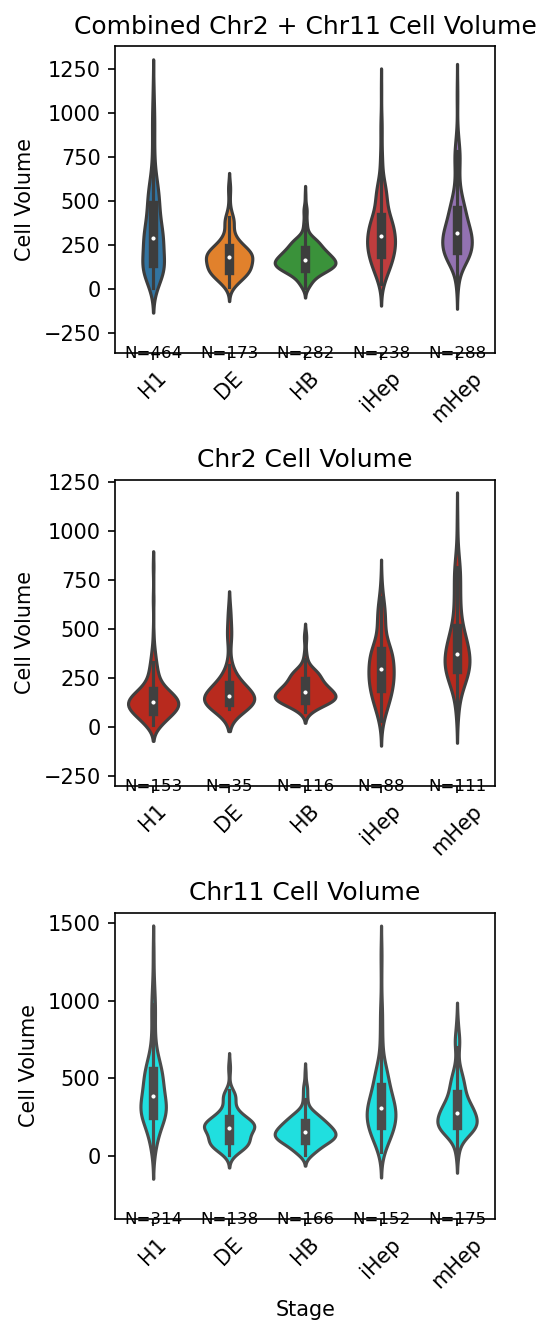

In [24]:
#cell volume
# Combine different chromosome territories
chr2_chromosome_territory_all['chrom'] = 'chr2'
chr11_chromosome_territory_all['chrom'] = 'chr11'
chromosome_territory_all = pd.concat([chr2_chromosome_territory_all, chr11_chromosome_territory_all])

# Function to remove outliers using the IQR method
def remove_outliers(df, column, lower_percentile=0.1, upper_percentile=0.9):
    Q1 = df[column].quantile(lower_percentile)
    Q3 = df[column].quantile(upper_percentile)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]

# Split and filter
filtered_combined = remove_outliers(chromosome_territory_all, 'cell_volumn')
filtered_chr2 = remove_outliers(chr2_chromosome_territory_all, 'cell_volumn')
filtered_chr11 = remove_outliers(chr11_chromosome_territory_all, 'cell_volumn')

# Plot setup: 3 subplots, vertically stacked
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(3.5, 9), dpi=150)
ordered_stages = ['H1', 'DE', 'HB', 'iHep', 'mHep']

# Helper function to add N labels
def add_n_labels(ax, df, y_offset=0.1):
    y_min, y_max = ax.get_ylim()
    for i, stage in enumerate(ordered_stages):
        count = len(df[df['stage'] == stage])
        ax.text(
            x=i,
            y=y_min - y_offset * (y_max - y_min),
            s=f"N={count}",
            ha='center',
            va='center',
            fontsize=8,
            color="black"
        )
    ax.set_ylim(y_min - y_offset * (y_max - y_min), y_max + 1)

# --- Plot Combined ---
sns.violinplot(ax=axes[0], data=filtered_combined, x='stage', y='cell_volumn',
               order=ordered_stages, inner='box', alpha=0.7)
axes[0].set_title('Combined Chr2 + Chr11 Cell Volume')
axes[0].set_xlabel('')
axes[0].set_ylabel('Cell Volume')
axes[0].tick_params(axis='x', rotation=45)
add_n_labels(axes[0], filtered_combined)

# --- Plot Chr2 ---
sns.violinplot(ax=axes[1], data=filtered_chr2, x='stage', y='cell_volumn',
               order=ordered_stages, inner='box', alpha=0.7, color='#D21404')
axes[1].set_title('Chr2 Cell Volume')
axes[1].set_xlabel('')
axes[1].set_ylabel('Cell Volume')
axes[1].tick_params(axis='x', rotation=45)
add_n_labels(axes[1], filtered_chr2)

# --- Plot Chr11 ---
sns.violinplot(ax=axes[2], data=filtered_chr11, x='stage', y='cell_volumn',
               order=ordered_stages, inner='box', alpha=0.7, color='cyan')
axes[2].set_title('Chr11 Cell Volume')
axes[2].set_xlabel('Stage')
axes[2].set_ylabel('Cell Volume')
axes[2].tick_params(axis='x', rotation=45)
add_n_labels(axes[2], filtered_chr11)

# Finalize and save
plt.tight_layout()
output_path = "/home/xiangru.huo-umw/scHiC/scripts/plot2/Cell_volume_chr2_chr11_combined.pdf"
plt.savefig(output_path, dpi=200, format="pdf", bbox_inches="tight")
plt.show()

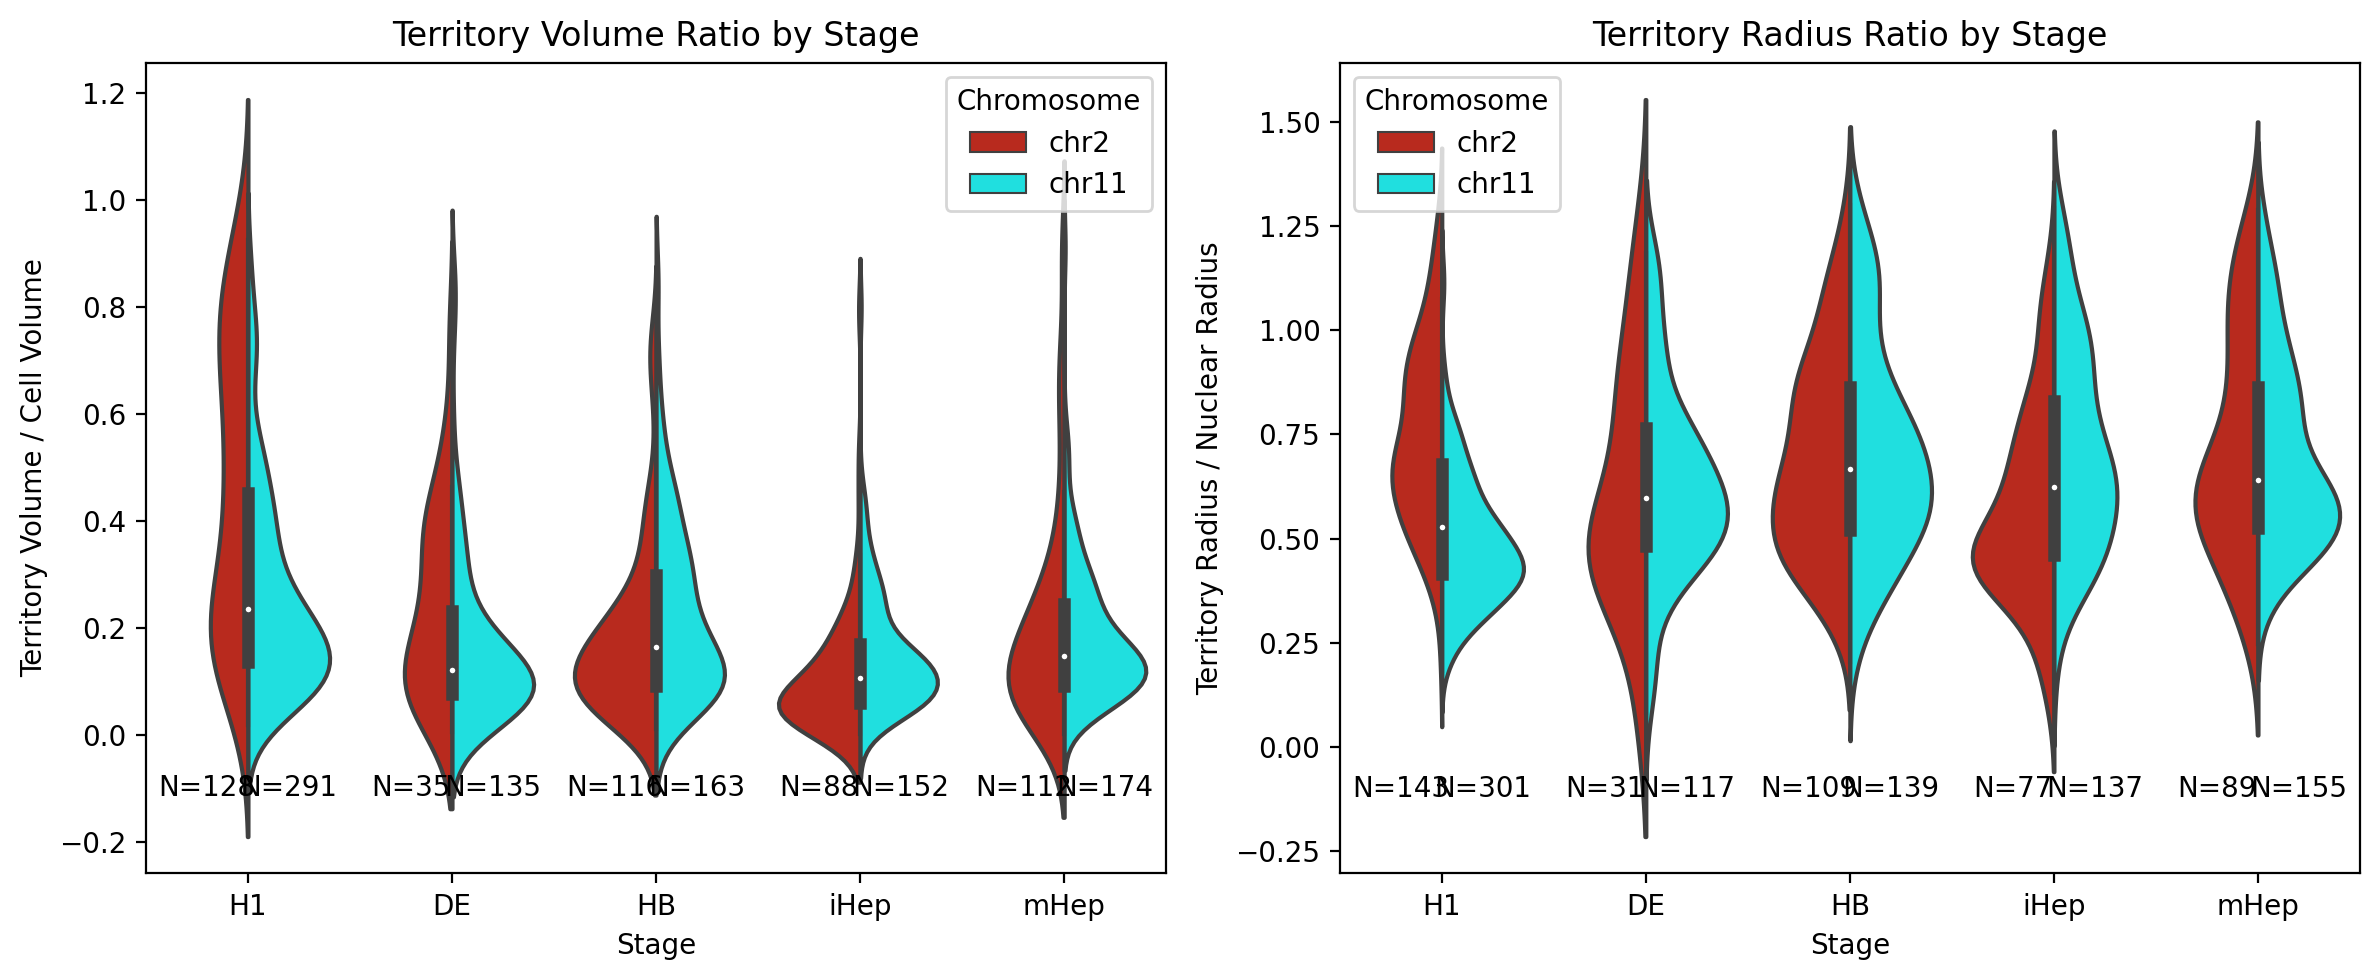

In [134]:
#chromosome territory volume and location
# Prepare data
chromosome_territory_all_vol = pd.concat([chr2_chromosome_territory_all, chr11_chromosome_territory_all])
chromosome_territory_all_vol = chromosome_territory_all_vol[
    chromosome_territory_all_vol['Territory_volumnofcell_ratio'] <= 1
]

chromosome_territory_all_rad = pd.concat([chr2_chromosome_territory_all, chr11_chromosome_territory_all])
chromosome_territory_all_rad = chromosome_territory_all_rad[
    chromosome_territory_all_rad['Territory_radius_mean_ratio'] <= 1.3
]

# Colors for chromosomes
palette = {"chr2": '#D21404', "chr11": "cyan"}

# Create subplots
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5), dpi=200)

# Plot Territory_volumnofcell_ratio
sns.violinplot(
    ax=axes[0],
    data=chromosome_territory_all_vol,
    x='stage',
    y='Territory_volumnofcell_ratio',
    hue='chr',
    split=True,
    palette=palette,
    alpha=0.7  
)

# Add N labels for each condition (chromosome and stage)
for i, stage in enumerate(chromosome_territory_all_vol['stage'].unique()):
    for j, chromosome in enumerate(['chr2', 'chr11']):
        count = len(chromosome_territory_all_vol[
            (chromosome_territory_all_vol['stage'] == stage) & 
            (chromosome_territory_all_vol['chr'] == chromosome)
        ])
        # Adjust x position based on stage and chromosome
        x_pos = i + (0.2 if chromosome == 'chr11' else -0.2)
        axes[0].text(
            x=x_pos,
            y=-0.1,  # Place text below the violins
            s=f"N={count}",
            ha='center',
            va='center',
            fontsize=10,
            color="black")

axes[0].set_title('Territory Volume Ratio by Stage')
axes[0].set_xlabel('Stage')
axes[0].set_ylabel('Territory Volume / Cell Volume')
axes[0].legend(title='Chromosome')

# Plot Territory_radius_mean_ratio
sns.violinplot(
    ax=axes[1],
    data=chromosome_territory_all_rad,
    x='stage',
    y='Territory_radius_mean_ratio',
    hue='chr',
    split=True,
    palette=palette,
    alpha=0.7  
)

# Add N labels for each condition (chromosome and stage)
for i, stage in enumerate(chromosome_territory_all_rad['stage'].unique()):
    for j, chromosome in enumerate(['chr2', 'chr11']):
        count = len(chromosome_territory_all_rad[
            (chromosome_territory_all_rad['stage'] == stage) & 
            (chromosome_territory_all_rad['chr'] == chromosome)
        ])
        # Adjust x position based on stage and chromosome
        x_pos = i + (0.2 if chromosome == 'chr11' else -0.2)
        axes[1].text(
            x=x_pos,
            y=-0.1,  # Place text below the violins
            s=f"N={count}",
            ha='center',
            va='center',
            fontsize=10,
            color="black")

axes[1].set_title('Territory Radius Ratio by Stage')
axes[1].set_xlabel('Stage')
axes[1].set_ylabel('Territory Radius / Nuclear Radius')
axes[1].legend(title='Chromosome')

# Adjust layout and save the plot
fig.tight_layout()

# Save the plot as a PDF
output_path = "/home/xiangru.huo-umw/scHiC/scripts/plot2/Chromosome_territory_colored.pdf"
plt.savefig(output_path, dpi=200, format="pdf", bbox_inches="tight")
plt.show()


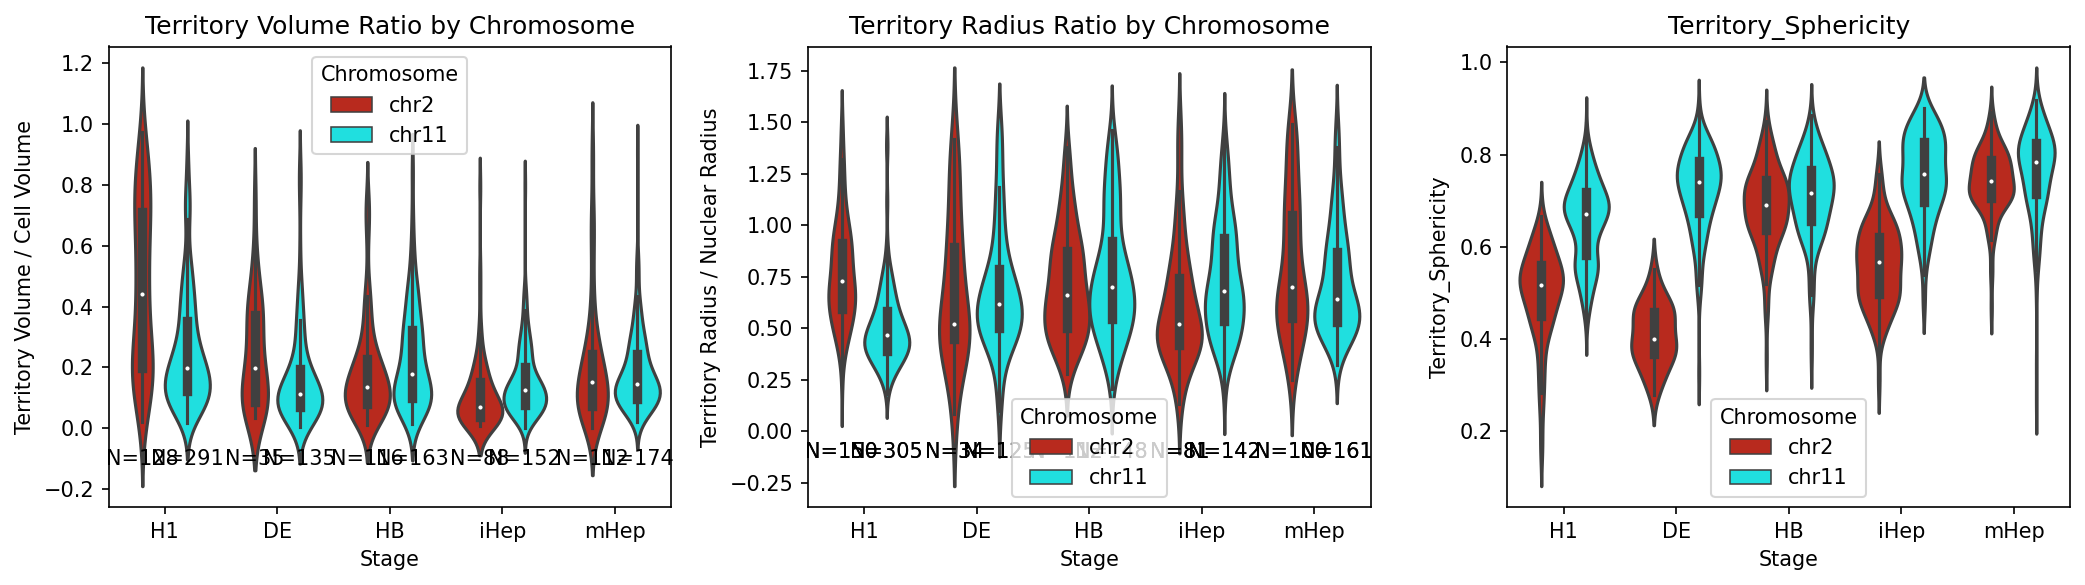

In [18]:
#chromosome territory volume and location
chromosome_territory_all_vol = pd.concat([chr2_chromosome_territory_all, chr11_chromosome_territory_all])
chromosome_territory_all_vol = chromosome_territory_all_vol[
    chromosome_territory_all_vol['Territory_volumnofcell_ratio'] <= 1
]

chromosome_territory_all_rad = pd.concat([chr2_chromosome_territory_all, chr11_chromosome_territory_all])
chromosome_territory_all_rad = chromosome_territory_all_rad[
    chromosome_territory_all_rad['Territory_radius_mean_ratio'] <= 1.5
]

# Colors for chromosomes
palette = {"chr2": '#D21404', "chr11": "cyan"}

# Create subplots
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(14, 4), dpi=150)

# Plot Territory_volumnofcell_ratio
sns.violinplot(
    ax=axes[0],
    data=chromosome_territory_all_vol,
    x='stage',
    y='Territory_volumnofcell_ratio',
    hue='chr',
    split=False,  # Each chromosome is a separate violin
    palette=palette,
    dodge=True ,  # Ensures violins are not shifted
    alpha=0.7  
)

# Add N labels for each condition (chromosome and stage)
for i, stage in enumerate(chromosome_territory_all_vol['stage'].unique()):
    for j, chromosome in enumerate(['chr2', 'chr11']):
        count = len(chromosome_territory_all_vol[
            (chromosome_territory_all_vol['stage'] == stage) & 
            (chromosome_territory_all_vol['chr'] == chromosome)
        ])
        # Adjust x position based on stage and chromosome
        x_pos = i + (0.2 if chromosome == 'chr11' else -0.2)
        axes[0].text(
            x=x_pos,
            y=-0.1,  # Place text below the violins
            s=f"N={count}",
            ha='center',
            va='center',
            fontsize=10,
            color="black")

axes[0].set_title('Territory Volume Ratio by Chromosome')
axes[0].set_xlabel('Stage')
axes[0].set_ylabel('Territory Volume / Cell Volume')
axes[0].legend(title='Chromosome')

# Plot Territory_radius_mean_ratio
sns.violinplot(
    ax=axes[1],
    data=chromosome_territory_all_rad,
    x='stage',
    y='Territory_radius_mean_ratio',
    hue='chr',
    split=False,  # Each chromosome is a separate violin
    palette=palette,
    dodge=True  , # Ensures violins are not shifted
    alpha=0.7  
)

# Add N labels for each condition (chromosome and stage)
for i, stage in enumerate(chromosome_territory_all_rad['stage'].unique()):
    for j, chromosome in enumerate(['chr2', 'chr11']):
        count = len(chromosome_territory_all_rad[
            (chromosome_territory_all_rad['stage'] == stage) & 
            (chromosome_territory_all_rad['chr'] == chromosome)
        ])
        # Adjust x position based on stage and chromosome
        x_pos = i + (0.2 if chromosome == 'chr11' else -0.2)
        axes[1].text(
            x=x_pos,
            y=-0.1,  # Place text below the violins
            s=f"N={count}",
            ha='center',
            va='center',
            fontsize=10,
            color="black")

axes[1].set_title('Territory Radius Ratio by Chromosome')
axes[1].set_xlabel('Stage')
axes[1].set_ylabel('Territory Radius / Nuclear Radius')
axes[1].legend(title='Chromosome')

# Plot Territory_radius_mean_ratio
sns.violinplot(
    ax=axes[2],
    data=chromosome_territory_all_rad,
    x='stage',
    y='Territory_Sphericity',
    hue='chr',
    split=False,  # Each chromosome is a separate violin
    palette=palette,
    dodge=True  , # Ensures violins are not shifted
    alpha=0.7  
)

# Add N labels for each condition (chromosome and stage)
for i, stage in enumerate(chromosome_territory_all_rad['stage'].unique()):
    for j, chromosome in enumerate(['chr2', 'chr11']):
        count = len(chromosome_territory_all_rad[
            (chromosome_territory_all_rad['stage'] == stage) & 
            (chromosome_territory_all_rad['chr'] == chromosome)
        ])
        # Adjust x position based on stage and chromosome
        x_pos = i + (0.2 if chromosome == 'chr11' else -0.2)
        axes[1].text(
            x=x_pos,
            y=-0.1,  # Place text below the violins
            s=f"N={count}",
            ha='center',
            va='center',
            fontsize=10,
            color="black")

axes[2].set_title('Territory_Sphericity')
axes[2].set_xlabel('Stage')
axes[2].set_ylabel('Territory_Sphericity')
axes[2].legend(title='Chromosome')


# Adjust layout and save the plot
fig.tight_layout()
output_path = "/home/xiangru.huo-umw/scHiC/scripts/plot2/Chromosome_territory_split.pdf"
plt.savefig(output_path, dpi=150, format="pdf", bbox_inches="tight")
plt.show()
